# 04 - Task 3: data preparation (UFPR-AMR)

Task 3 reads the value of an electricity meter from a photo: the input is an image, the output is the sequence of its 5 digits.

**Dataset:** UFPR-AMR (Laroca et al., 2019), https://web.inf.ufpr.br/vri/databases/ufpr-amr/. 2,000 photos of electricity meters taken in a warehouse of the Copel energy company (Paraná, Brazil) with three phone cameras, 2,340 x 4,160 to 3,120 x 4,160 pixels. Every counter has exactly 5 digits. Each image comes with a text file giving the camera, the reading, the position of the counter (x, y, w, h) and the position of each digit. The official split is 800 training / 400 validation / 800 test images, and we keep it.

The dataset was obtained by e-mail request for academic use only; it may not be redistributed, so it stays in `data/raw/` (not in the repository) and figures that show its images are only used in the report and slides.

In [1]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
sys.path.insert(0, os.path.abspath(".."))

import io
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

from src.config import AMR_CACHE, AMR_ZIP, CROP_MARGIN, FIGURES_DIR, IMG_H, IMG_W, NUM_DIGITS, REPORTS_DIR
from src.meter_data import digits_to_value, load_counters, make_augmenter, read_annotations

FIG_DIR = FIGURES_DIR / "meter"
FIG_DIR.mkdir(parents=True, exist_ok=True)
%matplotlib inline

## 1. Annotations

`read_annotations()` reads the 2,000 text files directly from the zip archive (no need to unzip 5 GB). Example of one annotation file:

```text
camera: iPhone 6s
reading: 07317
position: 1297 1631 526 116
    digit 1: 1303 1646 52 91
    ...
```

The reading is kept as text so that leading zeros are not lost.

In [2]:
meta = read_annotations()
meta["value"] = meta["reading"].astype(int)
print(len(meta), "images")
summary = pd.crosstab(meta["camera"], meta["split"], margins=True, margins_name="total")[["train", "val", "test", "total"]]
summary.to_csv(REPORTS_DIR / "meter_dataset_summary.csv")
summary

2000 images


split,train,val,test,total
camera,,,,
LG G3 D855,385,186,376,947
Samsung Galaxy J7 Prime,232,115,237,584
iPhone 6s,183,99,187,469
total,800,400,800,2000


In [3]:
meta.head()

,split,image,camera,reading,x,y,w,h,value
0,test,UFPR-AMR Dataset/testing/meter1201.jpg,LG G3 D855,01770,983,1966,326,135,1770
1,test,UFPR-AMR Dataset/testing/meter1202.jpg,LG G3 D855,05866,1026,1736,331,139,5866
2,test,UFPR-AMR Dataset/testing/meter1203.jpg,LG G3 D855,03218,1032,1739,279,101,3218
3,test,UFPR-AMR Dataset/testing/meter1204.jpg,LG G3 D855,01719,1048,1909,287,105,1719
4,test,UFPR-AMR Dataset/testing/meter1205.jpg,LG G3 D855,06739,939,1853,327,117,6739


## 2. Counter regions

         count    mean     std     min     25%     50%     75%      max
w       2000.0  674.49  233.21  238.00  487.00  661.00  843.00  1689.00
h       2000.0  177.51   44.96   80.00  144.00  170.00  205.00   405.00
aspect  2000.0    3.78    0.85    1.74    2.98    3.99    4.42     6.03


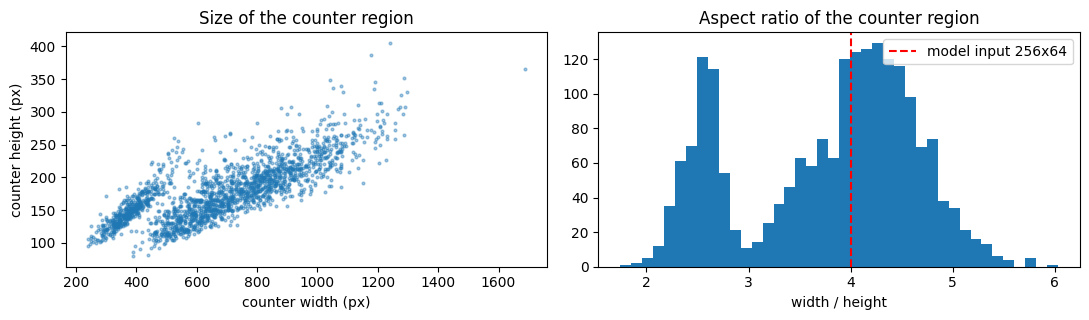

In [4]:
meta["aspect"] = meta["w"] / meta["h"]
print(meta[["w", "h", "aspect"]].describe().round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].scatter(meta["w"], meta["h"], s=4, alpha=0.4)
axes[0].set_xlabel("counter width (px)")
axes[0].set_ylabel("counter height (px)")
axes[0].set_title("Size of the counter region")
axes[1].hist(meta["aspect"], bins=40)
axes[1].axvline(IMG_W / IMG_H, color="red", ls="--", label=f"model input {IMG_W}x{IMG_H}")
axes[1].set_xlabel("width / height")
axes[1].set_title("Aspect ratio of the counter region")
axes[1].legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "counter_size.png", dpi=150, bbox_inches="tight")
plt.show()

The counter region is on average 674 x 178 pixels (from 238 x 80 to 1,689 x 405), always a small part of the photo. Its width is on average 3.8 times its height (median 4.0, range 1.7 to 6.0). The model input of 256 x 64 has a ratio of 4, so most counters are resized with little distortion; only the narrowest ones are stretched horizontally.

## 3. Digits and readings

how often each digit (columns 0-9) appears at each position:


,0,1,2,3,4,5,6,7,8,9
digit 1,904,622,219,89,56,38,24,19,12,17
digit 2,277,192,204,215,196,173,191,204,174,174
digit 3,227,205,188,205,203,175,197,204,183,213
digit 4,232,185,210,205,195,206,200,196,192,179
digit 5,187,217,183,219,198,230,209,177,193,187


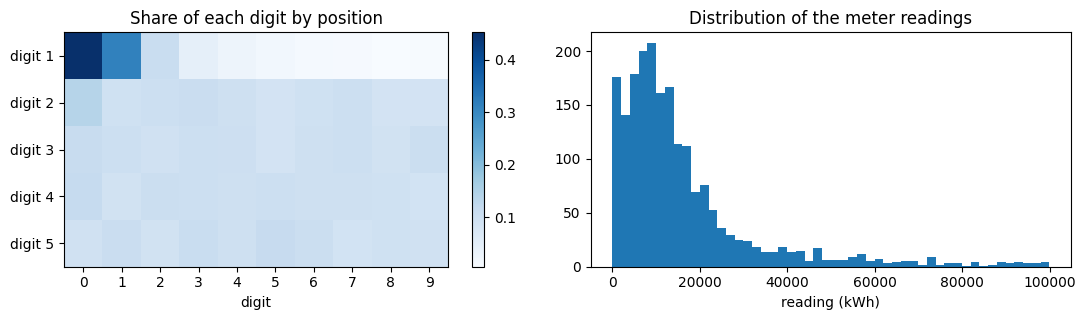

       count     mean      std  min     25%      50%      75%      max
split                                                                 
test   800.0  16463.0  17237.0  0.0  6317.0  11500.0  19326.0  99907.0
train  800.0  15419.0  15994.0  0.0  5874.0  10609.0  18779.0  98204.0
val    400.0  16436.0  17044.0  0.0  5993.0  11376.0  19816.0  99940.0


In [5]:
digits = np.array([[int(ch) for ch in r] for r in meta["reading"]])
freq = pd.DataFrame([np.bincount(digits[:, p], minlength=10) for p in range(NUM_DIGITS)],
                    index=[f"digit {p + 1}" for p in range(NUM_DIGITS)], columns=range(10))
print("how often each digit (columns 0-9) appears at each position:")
display(freq)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
im = axes[0].imshow(freq.values / len(meta), cmap="Blues", aspect="auto")
axes[0].set_xticks(range(10))
axes[0].set_yticks(range(NUM_DIGITS), freq.index)
axes[0].set_xlabel("digit")
axes[0].set_title("Share of each digit by position")
fig.colorbar(im, ax=axes[0])
axes[1].hist(meta["value"], bins=50)
axes[1].set_xlabel("reading (kWh)")
axes[1].set_title("Distribution of the meter readings")
plt.tight_layout()
fig.savefig(FIG_DIR / "digit_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(meta.groupby("split")["value"].describe().round(0))

- The first digit is 0 for 45 % of the meters and 1 for 31 %: most readings are below 20,000 kWh (median about 11,000). The model therefore sees few examples of large first digits (for example only 12 images have an 8 in the first position).
- Positions 2 to 5 use the ten digits almost equally often (between 9 % and 14 % each).
- The three splits have similar readings (median 10,609 / 11,376 / 11,500 kWh for train / validation / test).
- The first digit is worth 10,000 kWh, so a single wrong digit at that position gives a very large error in kWh. This matters when the readings are evaluated with MAE and RMSE.

## 4. Cropping the counter

The model does not need the whole photo: the counter region is given in the annotation, so it is cut out with a small margin (8 % of its width on the left and right, 15 % of its height above and below, so that no digit is cut) and resized to a fixed size of 64 x 256 pixels (RGB). 64 x 256 keeps the typical 4:1 shape of the counter. Because the photos are very large, the JPEG is decoded at half size first, which is still much more detail than needed for 64 x 256.

`load_counters()` does this once for all 2,000 images and saves the result in `data/raw/ufpr_amr_counters_64x256.npz`; the next notebooks load this file.

In [6]:
data = load_counters()
for split in ["train", "val", "test"]:
    print(f"{split:5s}: images {data[f'x_{split}'].shape}, labels {data[f'y_{split}'].shape}")
print("example label:", data["reading_train"][0], "->", data["y_train"][0].tolist(), "->", digits_to_value(data["y_train"][:1])[0])

train: images (800, 64, 256, 3), labels (800, 5)
val  : images (400, 64, 256, 3), labels (400, 5)
test : images (800, 64, 256, 3), labels (800, 5)
example label: 00001 -> [0, 0, 0, 0, 1] -> 1


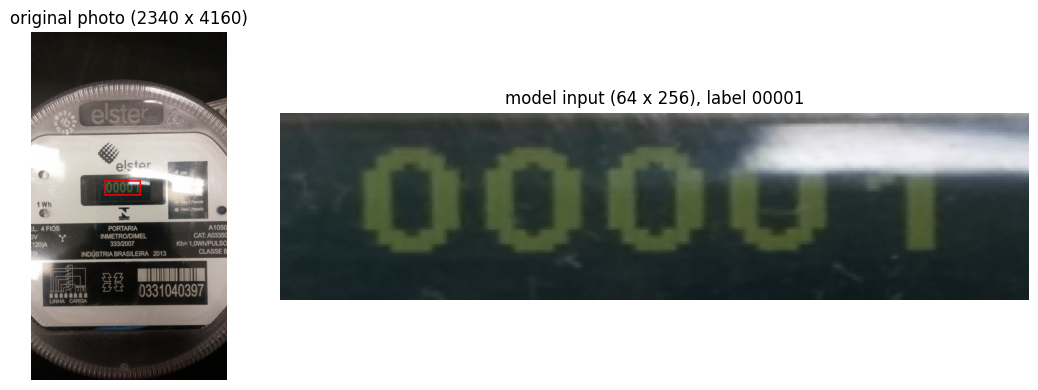

In [7]:
# một ảnh gốc với khung vùng số (vẽ trên ảnh thu nhỏ)
row = meta[meta["split"] == "train"].iloc[0]
with zipfile.ZipFile(AMR_ZIP) as z:
    img = Image.open(io.BytesIO(z.read(row["image"]))).convert("RGB")
small = img.resize((img.width // 6, img.height // 6))
draw = ImageDraw.Draw(small)
draw.rectangle([row["x"] / 6, row["y"] / 6, (row["x"] + row["w"]) / 6, (row["y"] + row["h"]) / 6], outline="red", width=3)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].imshow(small)
axes[0].set_title(f"original photo ({img.width} x {img.height})")
axes[1].imshow(data["x_train"][0])
axes[1].set_title(f"model input ({IMG_H} x {IMG_W}), label {data['reading_train'][0]}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "samples_full_and_crop.png", dpi=150, bbox_inches="tight")
plt.show()

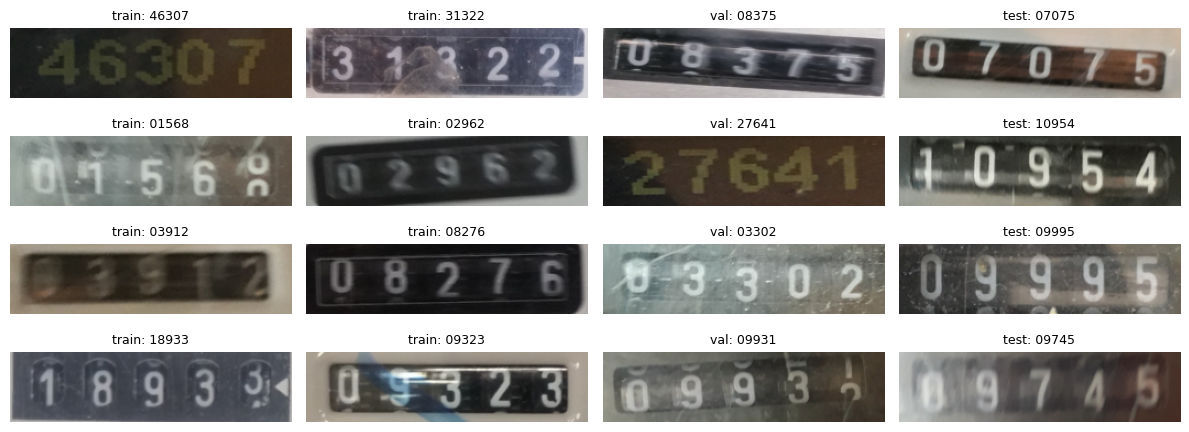

In [8]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 4, figsize=(12, 4.6))
for ax, split in zip(axes.T, ["train", "train", "val", "test"]):
    for a in ax:
        i = rng.integers(len(data[f"x_{split}"]))
        a.imshow(data[f"x_{split}"][i])
        a.set_title(f"{split}: {data[f'reading_{split}'][i]}", fontsize=9)
        a.axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "samples_crops.png", dpi=150, bbox_inches="tight")
plt.show()

The crops show different meter types (green digits on a dark display, white rolling wheels on black), different lighting, reflections and some blur. Some wheels are caught half-way between two values; in the examples we checked, such a digit is labelled with the lower value (a wheel between 2 and 3 is labelled 2), so the model has to learn this convention from the data.

## 5. Data augmentation

With only 800 training images, the model can easily memorise them. During training each image is therefore changed slightly at random every time it is used (Chapter 5.3): a very small rotation (up to ±3.6°), a shift, a zoom of ±10 %, and changes of brightness and contrast. Images are **not flipped**, because a flipped digit is no longer the same digit. The augmentation layers are part of the model and are only active during training; validation and test images are never changed.

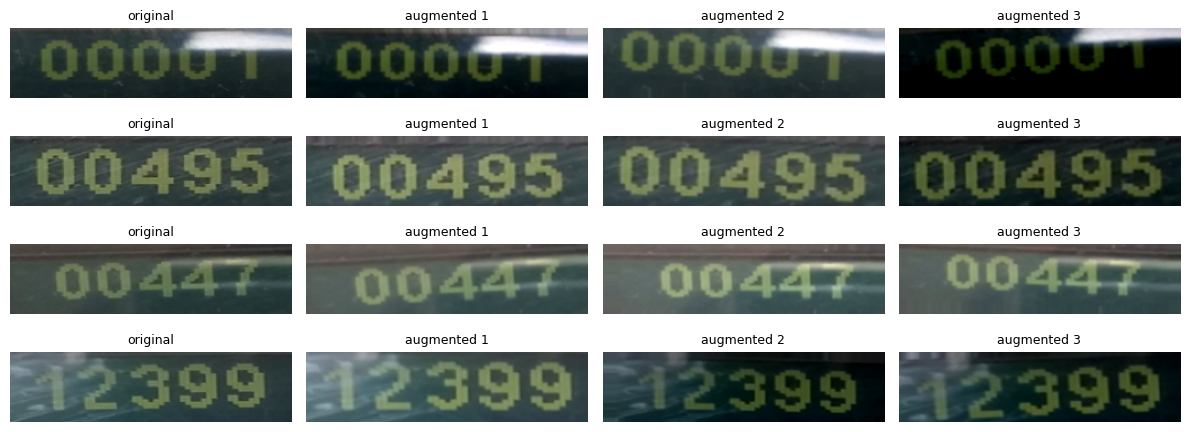

In [9]:
augment = make_augmenter()
originals = data["x_train"][:4].astype("float32")
fig, axes = plt.subplots(4, 4, figsize=(12, 4.6))
for r in range(4):
    axes[r, 0].imshow(originals[r].astype("uint8"))
    axes[r, 0].set_title("original", fontsize=9)
    for c in range(1, 4):
        aug = np.asarray(augment(originals[r:r + 1], training=True))[0]
        axes[r, c].imshow(np.clip(aug, 0, 255).astype("uint8"))
        axes[r, c].set_title(f"augmented {c}", fontsize=9)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "samples_augmentation.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

- 2,000 images (800 train / 400 validation / 800 test), three cameras, every reading has exactly 5 digits.
- Each counter is cut out with the annotation box plus a small margin and resized to 64 x 256 RGB; the crops are cached in `data/raw/ufpr_amr_counters_64x256.npz` for the next notebooks.
- The first digit is very unbalanced (mostly 0 or 1); the other positions are balanced.
- Training images are augmented on the fly (small rotation, shift, zoom, brightness, contrast; no flips).